In [30]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns
df = pd.read_csv("D:/ecomai/data/processed/cleaned.csv")

In [31]:
#Section 1 : Customer Analysis

print("Total unique customers:", df['CustomerID'].nunique())

order_per_customer = df.groupby('CustomerID')['InvoiceNo'].nunique()
print("Average Order Per Customer\n:")
print(order_per_customer.describe())

Total unique customers: 4338
Average Order Per Customer
:
count    4338.000000
mean        4.272015
std         7.697998
min         1.000000
25%         1.000000
50%         2.000000
75%         5.000000
max       209.000000
Name: InvoiceNo, dtype: float64


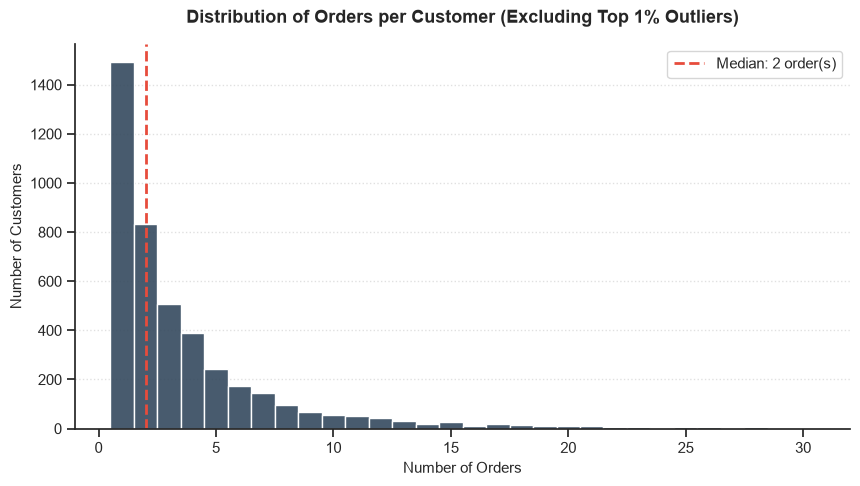

In [32]:
sns.set_theme(style="ticks")
fig, ax = plt.subplots(figsize=(10, 5))

# Filter out top 1% outliers for display clarity
p99 = order_per_customer.quantile(0.99)
filtered_orders = order_per_customer[order_per_customer <= p99]

sns.histplot(
    filtered_orders, 
    discrete=True,  # Treats discrete integer order counts cleanly
    color="#34495e", 
    edgecolor="white",
    alpha=0.9,
    ax=ax
)

# Annotate median
median_val = order_per_customer.median()
ax.axvline(median_val, color="#e74c3c", linestyle="--", linewidth=2, label=f"Median: {median_val:.0f} order(s)")

# Labels & Annotations
plt.title("Distribution of Orders per Customer (Excluding Top 1% Outliers)", fontsize=13, fontweight="bold", pad=15)
plt.xlabel("Number of Orders", fontsize=11)
plt.ylabel("Number of Customers", fontsize=11)
plt.legend(frameon=True)

sns.despine()
plt.grid(axis='y', linestyle=':', alpha=0.6)

plt.savefig(
    r'D:\ecomai\dashboard\Avg_orders_per_customer.png', 
    dpi=300, 
    bbox_inches='tight'
)
plt.show()

### 📊 Key Observations & Insights: Orders per Customer Distribution

* **Single-Order Dominance:** The majority of customers (~1,500+) have placed only **1 order**. This indicates a high proportion of one-time buyers and points to a potential gap in immediate post-purchase retention or onboarding.
* **Central Tendency:** The **median is 2 orders**, meaning half of the overall customer base places 1 or 2 orders, while the remaining half makes 2 or more purchases.
* **Right-Skewed Distribution (Power-Law Tail):** The distribution displays a steep decay as order counts increase. Very few customers advance beyond 5 to 10 purchases, highlighting a sharp drop-off in customer lifetime frequency.
* **High-Value Loyal Segment:** Despite the rapid drop-off, a long tail extends up to ~30 orders (excluding the top 1% extreme outliers). This represents the highly loyal core customer segment driving repeat revenue.

---

#### 💡 Key Takeaways & Recommendations:
1. **Focus on the 1st $\rightarrow$ 2nd Order Transition:** Since the biggest drop occurs after order #1, targeted post-purchase email campaigns or first-repeat discounts could yield high returns.
2. **VIP / Loyalty Program:** Identify and nurture the subset of users placing 5+ orders, as they make up the loyal long tail of the business.

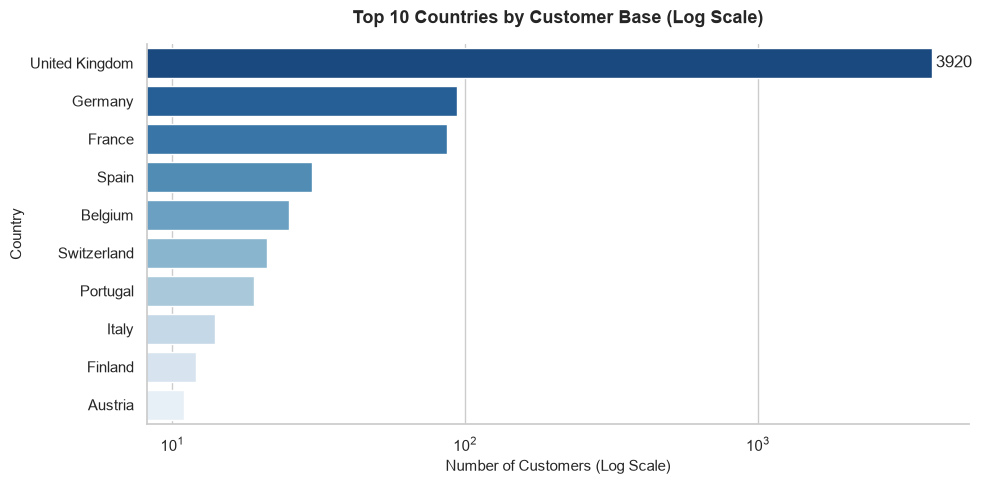

In [44]:

# Take top 10 countries including the UK
top_10_countries = country_counts.head(10)

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Horizontal barplot with log scale
ax = sns.barplot(
    x=top_10_countries.values, 
    y=top_10_countries.index,
    hue=top_10_countries.index,
    palette="Blues_r",
    legend=False
)

# Apply log scale to X-axis to accommodate the UK gap
ax.set_xscale("log")

# Add exact count labels on the bars
ax.bar_label(ax.containers[0], padding=3)

plt.title('Top 10 Countries by Customer Base (Log Scale)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Number of Customers (Log Scale)', fontsize=11)
plt.ylabel('Country', fontsize=11)

sns.despine()
plt.tight_layout()
plt.savefig(
    r'D:\ecomai\dashboard\Top countries by customer.png', 
    dpi=300, 
    bbox_inches='tight'
)
plt.show()

     📊 Key Observations: Top 10 Countries (Including UK)

* **Dominant Core Market:** The **United Kingdom** leads with **~3,900 customers**, outperforming second-place **Germany** by a factor of over 30x.
* **Log-Scale Perspective:** Plotted on a logarithmic scale, international markets show a steady distribution ranging from **Germany (~100+)** down to **Austria (~10+)**.
* **Geographic Concentration:** The entire top 10 customer base is concentrated within European nations, signaling strong regional brand awareness.

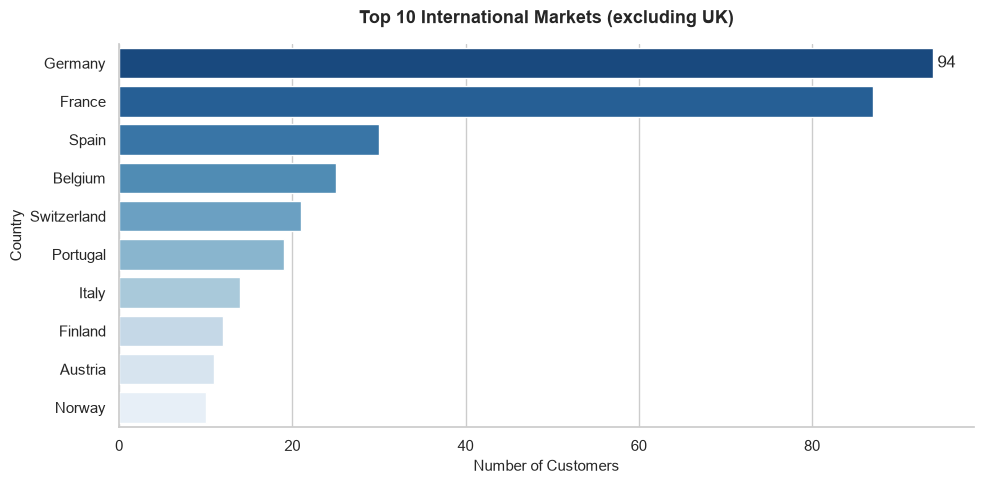

In [45]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filter out UK for secondary analysis
non_uk_data = country_counts[country_counts.index != 'United Kingdom'].head(10)

plt.figure(figsize=(10, 5))
sns.set_theme(style="whitegrid")

# Updated barplot line to fix the FutureWarning
ax = sns.barplot(
    x=non_uk_data.values, 
    y=non_uk_data.index,
    hue=non_uk_data.index,  # Assign categorical variable to hue
    palette="Blues_r",
    legend=False            # Suppress unnecessary legend
)

# Add data labels on bars
ax.bar_label(ax.containers[0], padding=3)

plt.title('Top 10 International Markets (excluding UK)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Number of Customers', fontsize=11)
plt.ylabel('Country', fontsize=11)

sns.despine()
plt.tight_layout()
plt.savefig(
    r'D:\ecomai\dashboard\Top_International_Market.png', 
    dpi=300, 
    bbox_inches='tight'
)
plt.show()

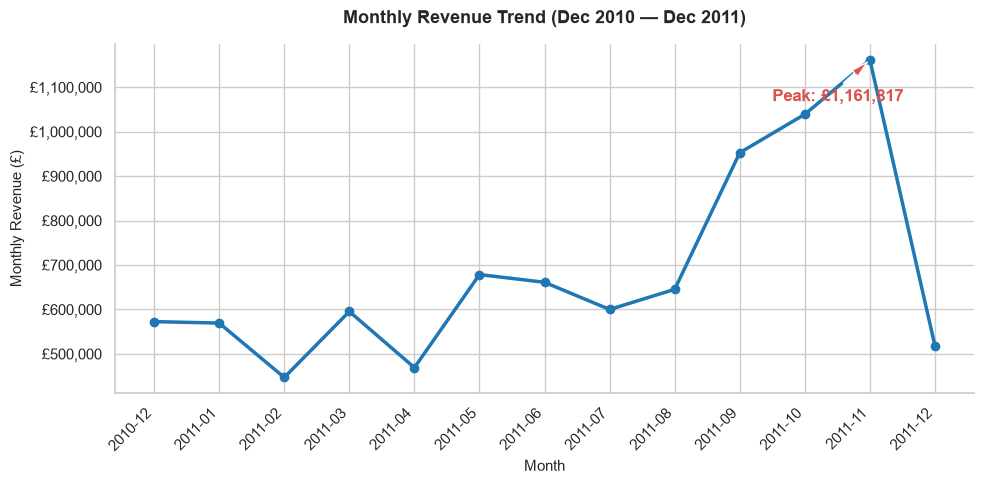

In [41]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd
import seaborn as sns

# 1. Prepare data
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])
df['Month'] = df['InvoiceDate'].dt.to_period('M')
monthly_revenue = df.groupby('Month')['TotalPrice'].sum()

# Convert PeriodIndex to string for clean tick formatting
x_labels = monthly_revenue.index.astype(str)
y_values = monthly_revenue.values

# 2. Set theme and figure
sns.set_theme(style="whitegrid")
fig, ax = plt.subplots(figsize=(10, 5))

# 3. Plot line trend
ax.plot(
    x_labels, 
    y_values, 
    color="#1f77b4", 
    linewidth=2.5, 
    marker="o", 
    markersize=6
)

# 4. Highlight the peak revenue month
max_idx = y_values.argmax()
ax.annotate(
    f'Peak: £{y_values[max_idx]:,.0f}',
    xy=(max_idx, y_values[max_idx]),
    xytext=(max_idx - 1.5, y_values[max_idx] * 0.92),
    arrowprops=dict(facecolor='#d9534f', shrink=0.08, width=1, headwidth=6),
    fontweight='bold',
    color='#d9534f'
)

# 5. Styling & Formatting
plt.title('Monthly Revenue Trend (Dec 2010 — Dec 2011)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Month', fontsize=11)
plt.ylabel('Monthly Revenue (£)', fontsize=11)
plt.xticks(rotation=45, ha='right')

ax.yaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'£{x:,.0f}'))
sns.despine()

# 6. Save and Display (tight_layout BEFORE savefig)
plt.tight_layout()
plt.savefig(
    r'D:\ecomai\dashboard\monthly_revenue_Trend.png', 
    dpi=300, 
    bbox_inches='tight'
)
plt.show()

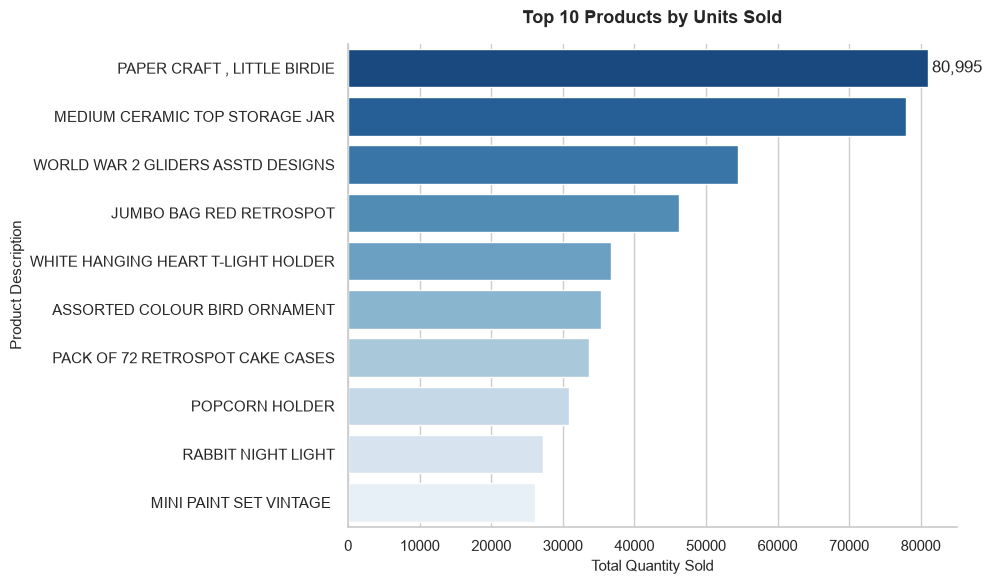

In [43]:
import matplotlib.pyplot as plt
import seaborn as sns

# Extract top 10 products directly from your pre-cleaned grouped data
top_products = (
    df.groupby('product')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# Plot setup
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

ax = sns.barplot(
    x=top_products.values,
    y=top_products.index,
    hue=top_products.index,
    palette="Blues_r",
    legend=False
)

# Add exact numeric labels on the end of each bar
ax.bar_label(ax.containers[0], fmt='{:,.0f}', padding=3)

# Titles & Axes
plt.title('Top 10 Products by Units Sold', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Total Quantity Sold', fontsize=11)
plt.ylabel('Product Description', fontsize=11)

sns.despine()
plt.tight_layout()

# Save image before showing
plt.savefig(
    r'D:\ecomai\dashboard\top_10_products.png', 
    dpi=300, 
    bbox_inches='tight'
)
plt.show()

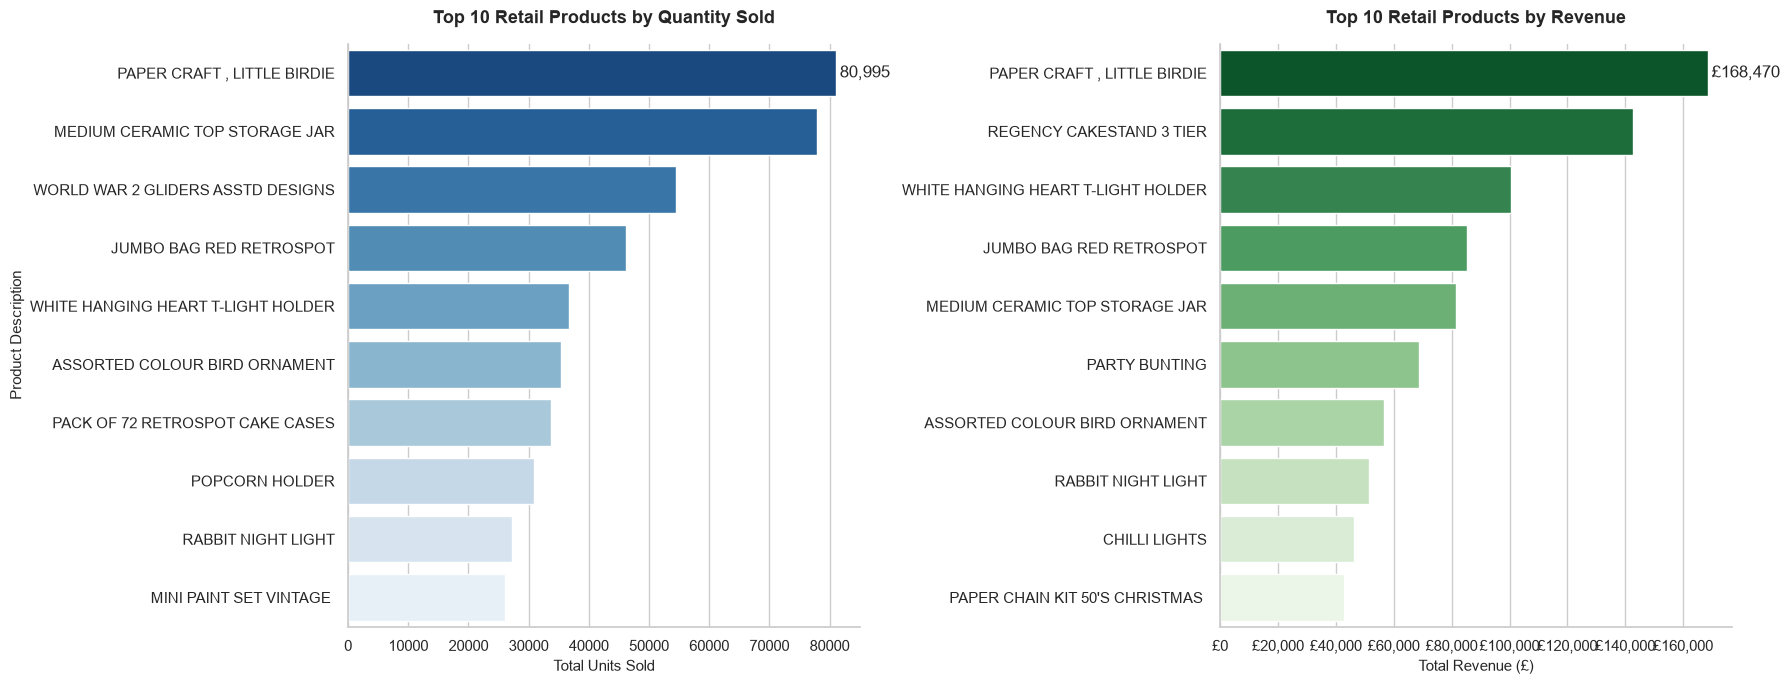

In [49]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# 1. Define non-product / operational descriptions to exclude
non_products = [
    'POSTAGE', 'MANUAL', 'CARRIAGE', 'DOTCOM POSTAGE', 
    'BANK CHARGES', 'AMAZON FEE', 'SAMPLES', 'ADJUSTMENT'
]

# 2. Filter dataframe for true retail products only
df_clean_products = df[~df['Description'].str.upper().str.strip().isin(non_products)].copy()

# 3. Calculate metrics on filtered product data
top_selling = (
    df_clean_products.groupby('Description')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

top_revenue = (
    df_clean_products.groupby('Description')['Revenue']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

# 4. Plotting Subplots
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

# Subplot 1: Top Selling Products
ax1 = sns.barplot(
    x=top_selling.values,
    y=top_selling.index,
    hue=top_selling.index,
    palette="Blues_r",
    legend=False,
    ax=axes[0]
)
ax1.set_title('Top 10 Retail Products by Quantity Sold', fontsize=13, fontweight='bold', pad=15)
ax1.set_xlabel('Total Units Sold', fontsize=11)
ax1.set_ylabel('Product Description', fontsize=11)
ax1.bar_label(ax1.containers[0], fmt='{:,.0f}', padding=3)

# Subplot 2: Highest Revenue Products
ax2 = sns.barplot(
    x=top_revenue.values,
    y=top_revenue.index,
    hue=top_revenue.index,
    palette="Greens_r",
    legend=False,
    ax=axes[1]
)
ax2.set_title('Top 10 Retail Products by Revenue', fontsize=13, fontweight='bold', pad=15)
ax2.set_xlabel('Total Revenue (£)', fontsize=11)
ax2.set_ylabel('', fontsize=11)
ax2.bar_label(ax2.containers[0], fmt='£{:,.0f}', padding=3)
ax2.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, p: f'£{x:,.0f}'))

sns.despine()
plt.tight_layout()

plt.savefig(
    r'D:\ecomai\dashboard\product_analysis_cleaned.png', 
    dpi=300, 
    bbox_inches='tight'
)
plt.show()

### 🧹 Data Cleaning Note: Filtering Operational Service Fees

* **Excluded Service Items:** Non-inventory transactions such as `POSTAGE`, `MANUAL`, `CARRIAGE`, and administrative fees were removed prior to product-level aggregation.
* **True Catalog Performance:** Removing shipping and manual adjustments prevents service fee inflation and ensures the charts reflect genuine physical product demand.

In [52]:
# Save cleaned dataframe with calculated columns (Revenue, Month, etc.)
df.to_csv(
    r'D:\ecomai\data\processed\cleaned_ecommerce_data.csv', 
    index=False
)